# 2. Описательная статистика. Меры центральной тенденции в Python

### Импорты

In [21]:
! pip install PyQt5==5.15.10

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/6.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.8 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.8 MB ? eta -:--:--
   --- ------------------------------------ 0.5/6.8 MB 1.9 MB/s eta 0:00:04
   ---- ----------------------------------- 0.8/6.8 MB 1.5 MB/s eta 0:00:05
   ---- ----------------------------------- 0.8/6.8 MB 1.5 MB/s eta 0:00:05
   ------ --------------------------------- 1.0/6.8 MB 1.1 MB/s eta 0:00:06
   --------- ------------------------------ 1.6/6.8 MB 1.2 MB/s eta 0:00:05
   ------------ --------------------------- 2.1/6.8 MB 1.4 MB/s eta 0:00:04
   --------------- ------------------------ 2.6/6.8 MB 1.6 MB/s eta 0:00:03
   ------------------ --------------------- 3.1/6.8 MB 1.7 MB/s eta 0:00:03
   --------------------- ------------------ 3.7/6.8 MB 1.8 MB/s eta 0:00:02
   ------------------------ ---

In [22]:
import pandas as pd
from ydata_profiling import ProfileReport
import statistics
import matplotlib.pyplot as plt  # библиотека визуализации
from scipy import stats  # библиотека для расчетов

In [26]:
# Исправление возможных ошибок отображения в ноутбуках
%matplotlib inline

In [2]:
df = pd.read_csv(
    "data/wine_cleared.zip"
)

In [3]:
profile = ProfileReport(df, title="Pandas Profiling Report")

profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 13/13 [00:08<00:00,  1.56it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

### Задание 2.3

In [6]:
statistics.mean(df['price'])

35.363389129985535

### Задание 2.4

In [7]:
df['price'].sum() / len(df['price'])

35.363389129985535

### Задание 2.5

In [8]:
statistics.median(df['price'])

28.0

### Задание 2.6

In [12]:
s = sorted(df['price'])
e = len(s) % 2
if(e > 0):
    r = s[int(len(s)/2)]
else:
    r = (s[int(len(s)/2) - 1] + s[int(len(s)/2)]) / 2

r

28.0

### Задание 2.7

In [14]:
statistics.multimode(df['price'])

[35.363389129985535]

### Задание 2.8

In [15]:
df['price'].mode()

0    35.363389
Name: price, dtype: float64

# 3. Корреляция

### Задание 3.3


In [17]:
df.corr(numeric_only=True)

,Unnamed: 0,points,price
Unnamed: 0,1.000000,0.007124,0.004652
points,0.007124,1.000000,0.402137
price,0.004652,0.402137,1.000000


# 4. Типы корреляций. Корреляция Пирсона

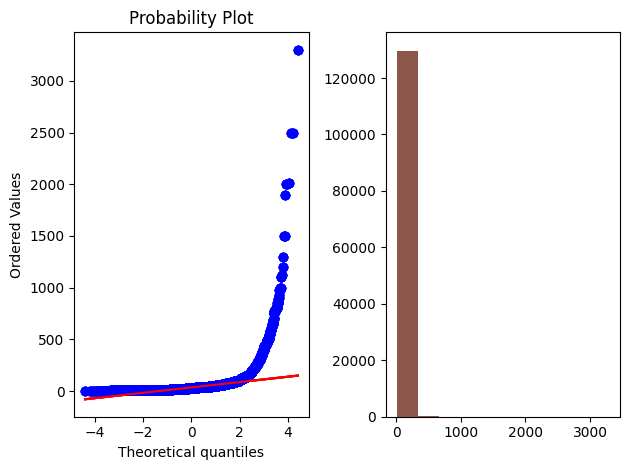

In [27]:


plt.subplot(1, 2, 1)  # задаем сетку рисунка количество строк и столбцов
stats.probplot(df["price"], plot=plt)  # qq plot

plt.subplot(1, 2, 2)  # располагаем второй рисунок рядом
plt.hist(df["price"])  # гистограмма распределения признака

plt.tight_layout()  # чтобы графики не наезжали другу на друга, используем tight_layout

plt.show()  # просмотр графика

### Задание 4.2

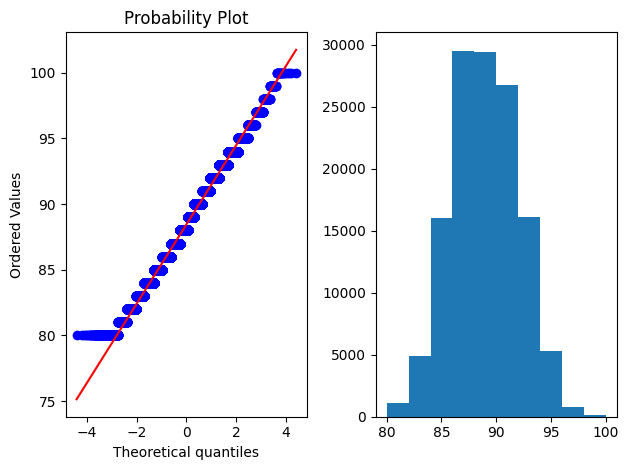

In [28]:
plt.subplot(1, 2, 1)  # задаем сетку рисунка количество строк и столбцов
stats.probplot(df["points"], plot=plt)  # qq plot

plt.subplot(1, 2, 2)  # располагаем второй рисунок рядом
plt.hist(df["points"])  # гистограмма распределения признака

plt.tight_layout()  # чтобы графики не наезжали другу на друга, используем tight_layout

plt.show()  # просмотр графика

# 5. Типы корреляций. Ранговые корреляции

## Корреляция Спирмена

### Задание 5.1

Рассчитайте коэффициент корреляции Спирмена для признаков point и price. Ответ округлите до сотых.

In [31]:
df['price'].corr(df['points'], method='spearman')

0.5810945611742083

## Корреляция Кендалла

### Задание 5.2

Рассчитайте коэффициент корреляции Кендалла для признаков point и price. Ответ округлите до сотых.

In [32]:
df["price"].corr(df["points"], method="kendall")

0.433497561218535

## Корреляция Мэтьюса

In [ ]:
! pip install scikit-learn

In [34]:
from sklearn.metrics import matthews_corrcoef

### Задание 5.3

Выполните приведённый выше код и выпишите получившееся значение коэффициента корреляции Мэтьюса. Округлите ответ до сотых.

In [35]:
x = [+1, -1, +1, +1]  # список значений признака х
y = [+1, +1, +1, -1]  # список значений признака y

matthews_corrcoef(x, y)  # рассчитаем коэффициент корреляции Мэтьюса

-0.3333333333333333

# 6. Визуализация корреляций. Матрица корреляций. График рассеивания. Парные отношения в наборе данных

In [37]:
df = pd.read_csv("data/model.zip")

## Матрица корреляций

### Задание 6.1

Постройте матрицу корреляций для датасета. В ответ впишите самый высокий коэффициент корреляции. Ответ округлите до сотых.

In [39]:
df.corr(numeric_only=True)

,Year,Waist,Hips,Height,Weight,BMI,Waist/Hip
Year,1.000000,0.292518,-0.281576,0.284482,-0.010753,0.025309,0.458945
Waist,0.292518,1.000000,0.283060,0.372637,0.452704,0.136549,0.742284
Hips,-0.281576,0.283060,1.000000,0.228054,0.541836,0.211395,-0.422412
Height,0.284482,0.372637,0.228054,1.000000,0.706569,-0.037934,0.198754
Weight,-0.010753,0.452704,0.541836,0.706569,1.000000,0.212701,0.067543
BMI,0.025309,0.136549,0.211395,-0.037934,0.212701,1.000000,-0.010173
Waist/Hip,0.458945,0.742284,-0.422412,0.198754,0.067543,-0.010173,1.000000


## Тепловая матрица корреляций

In [40]:
import seaborn as sns

<Axes: >

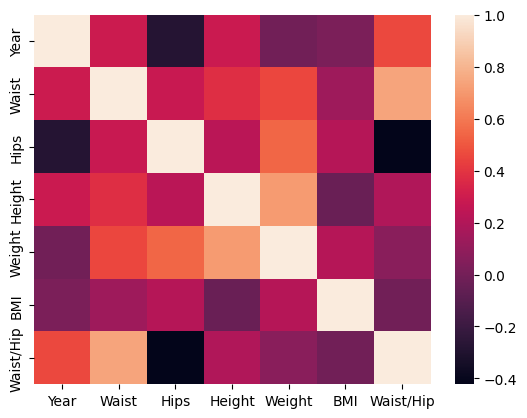

In [41]:
sns.heatmap(df.corr(numeric_only=True))

<Axes: >

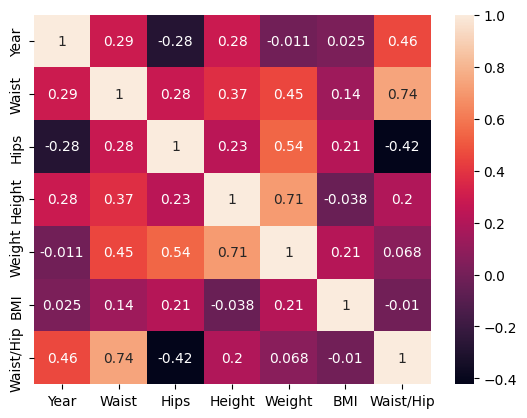

In [42]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## Scatterplot

<Axes: xlabel='Waist/Hip', ylabel='Waist'>

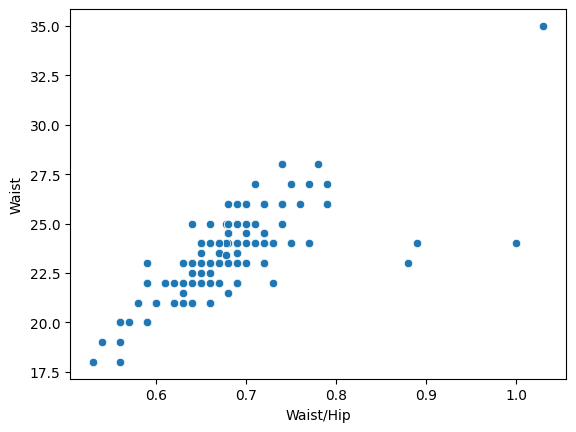

In [44]:
sns.scatterplot(data=df, x="Waist/Hip", y="Waist")

<Axes: xlabel='Weight', ylabel='Year'>

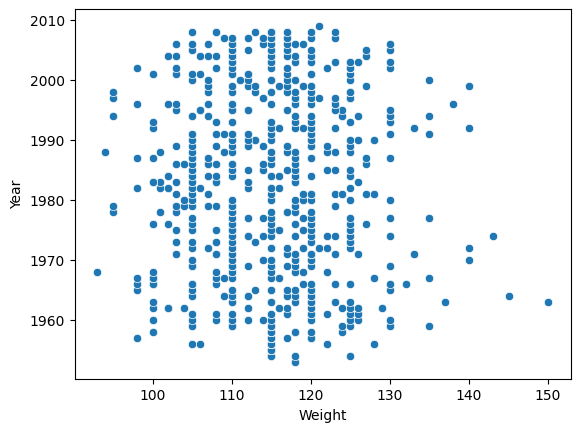

In [45]:
sns.scatterplot(data=df, x="Weight", y="Year")

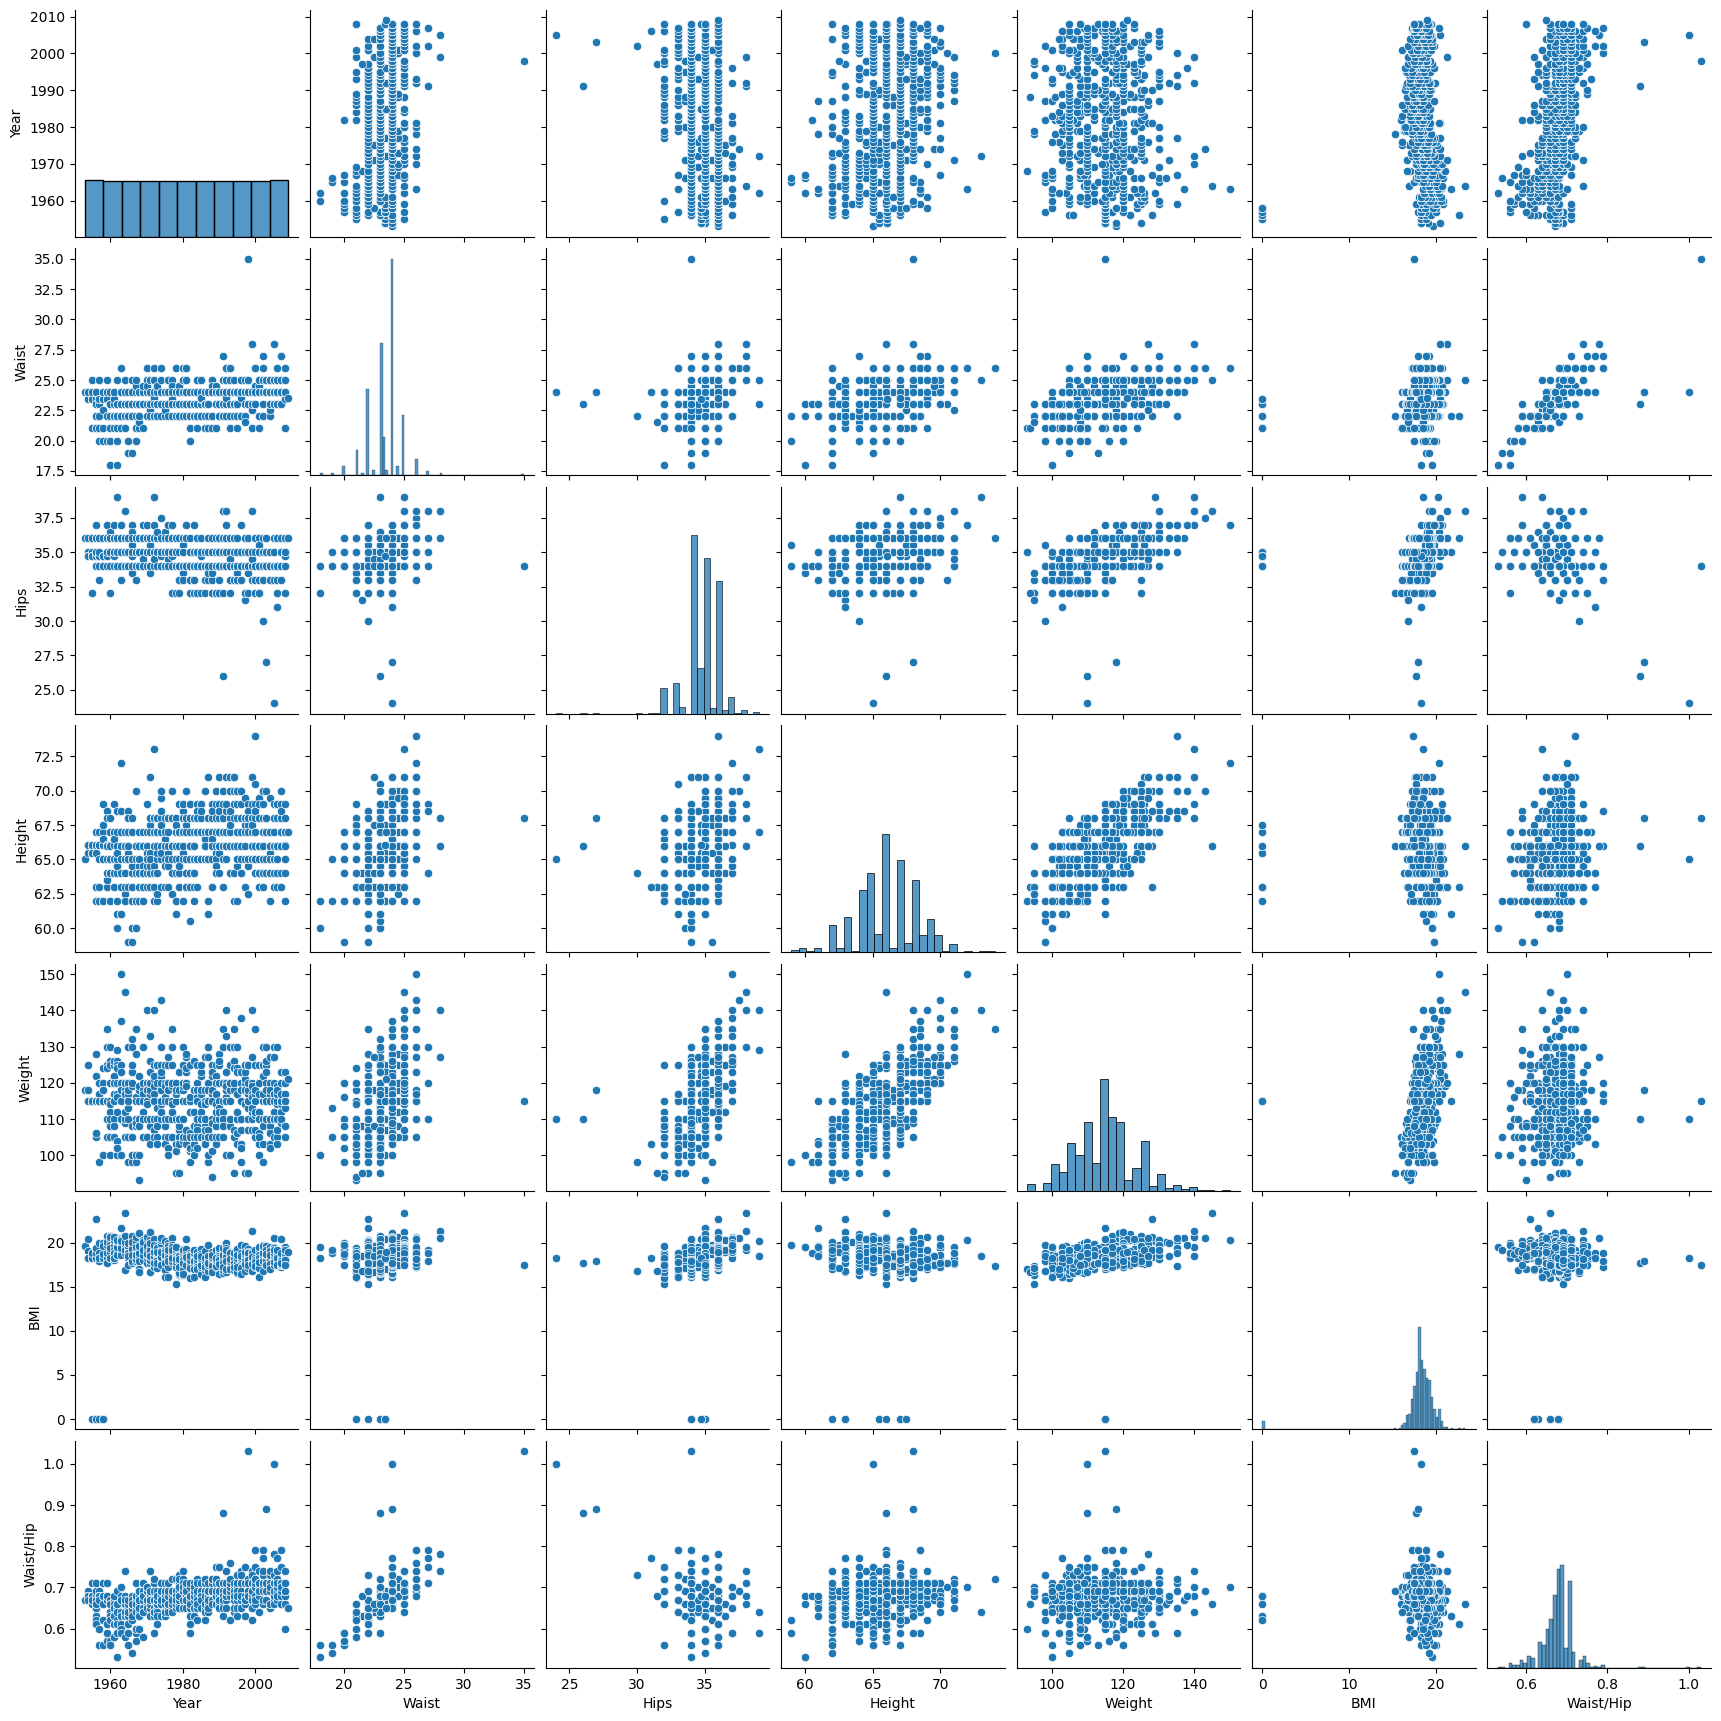

In [46]:
sns.pairplot(df)

### Задание 6.3

Посчитайте коэффициент корреляции между признаками Weight (вес модели) и Height (рост модели). Ответ округлите до сотых.

In [47]:
df['Weight'].corr(df['Height'])

0.7065690261409528

### Задание 7.2

Рассчитайте среднее значение признаков при помощи библиотеки statistics для признаков weight и height. Ответ округлите до сотых.

In [48]:
statistics.mean(df['Weight'])

114.93606557377049

In [49]:
statistics.mean(df['Height'])

66.05725806451613

### Задание 7.3

Постройте матрицы визуализации корреляций, диаграммы рассеивания, проанализируйте и выполните задание.

<Axes: >

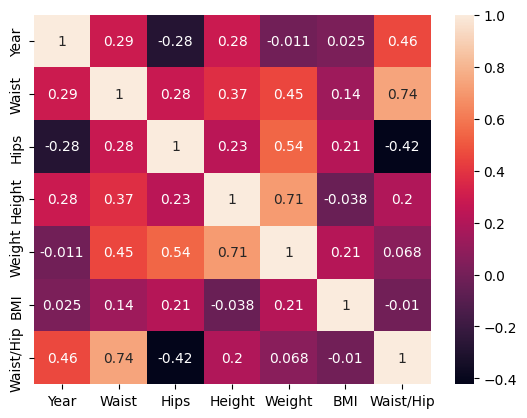

In [52]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

<Axes: xlabel='Waist', ylabel='BMI'>

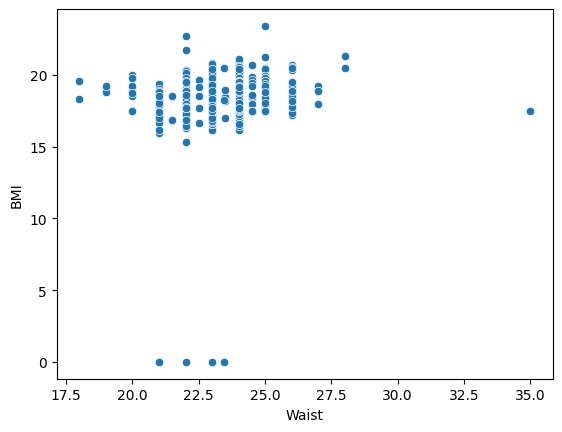

In [51]:
sns.scatterplot(data=df, x="Waist", y="BMI")

<Axes: xlabel='Waist', ylabel='Weight'>

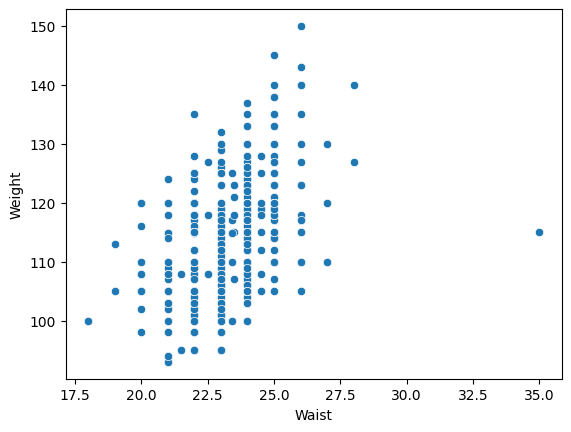

In [53]:
sns.scatterplot(data=df, x="Waist", y="Weight")